### Imports

In [203]:
import os
import warnings 
import random 
import copy
import glob 

import pandas as pd 
import sklearn 
import numpy as np

import matplotlib.pyplot as plt 
from tqdm.auto import tqdm 
from torchinfo import summary

import torch
from torch import nn 
from torch .utils.data import DataLoader, Dataset 
import torch.nn.functional as F
from torchvision import transforms 
from torchvision.transforms import v2
import cv2
import pydicom
from sklearn.metrics import roc_auc_score

from sklearn.model_selection import GroupKFold

import timm

warnings.filterwarnings("ignore")
print("All imported.")

All imported.


In [204]:
device = torch.device("mps"
if torch.backends.mps.is_available()
else "cuda"
if torch.cuda.is_available()
else "cpu")

print(f"Device: '{device}'")

Device: 'cuda'


In [205]:
SEED = 2026
N_SPLITS = 5
BATCH_SIZE = 8
NUM_EPOCHS = 5
LR = 2e-4

def seed_everything(seed=42):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic=(True)
    torch.backends.cudnn.benchmark=(False)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything(SEED)
print(f"General seed: {SEED}")

General seed: 2026


In [206]:
DATA_DIR = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

In [207]:
TARGET_COLS = [
    'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 
    'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 
    'Synovitis', "Baker's", 'Contusion', 'Fracture'
]

In [208]:
for item in os.listdir(DATA_DIR):
    full_path = os.path.join(DATA_DIR, item)
    if os.path.isdir(full_path):
        print(full_path)

/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series
/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series


### Download data

In [209]:
paths = []
for patient in os.listdir(os.path.join(DATA_DIR, "train_series")):
    files = glob.glob(
        os.path.join(DATA_DIR, "train_series", patient, "**", "*.dcm"),
        recursive=True,
    )
    if files:
        paths.extend(files)
    if len(paths) >= 5:
        break

for path in paths[:5]:
    print(path)

/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10843463954622076609489312662891432839/1.2.826.0.1.3680043.8.498.28798546215369442215420222435134673142/1.2.826.0.1.3680043.8.498.12486678153168904030743072482872142065.dcm
/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10843463954622076609489312662891432839/1.2.826.0.1.3680043.8.498.28798546215369442215420222435134673142/1.2.826.0.1.3680043.8.498.86700687663805155070115680323395754377.dcm
/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10843463954622076609489312662891432839/1.2.826.0.1.3680043.8.498.28798546215369442215420222435134673142/1.2.826.0.1.3680043.8.498.40362622123295797247686695535473040667.dcm
/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10843463954622076609489312662891432839/1.2.826.0.1.3680043.8.498.287985462153694422154202

All dcm files in train: 207
Shape image: (512, 512)
Type data image: int16


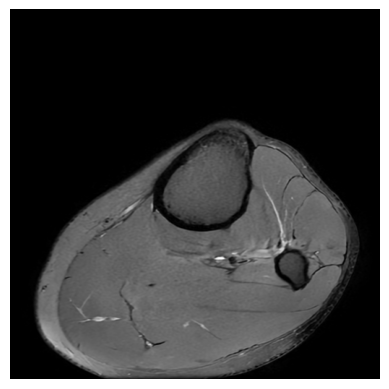

In [210]:
random_patient = random.choice(
    os.listdir(os.path.join(DATA_DIR, "train_series"))
)
all_dcm_files = glob.glob(
    os.path.join(DATA_DIR, "train_series", random_patient, "**", "*.dcm"),
    recursive=True,
)
print(f"All dcm files in train: {len(all_dcm_files)}")

random_dcm_path = random.choice(all_dcm_files)
dicom_data = pydicom.dcmread(random_dcm_path)
image_array = dicom_data.pixel_array

print(f"Shape image: {image_array.shape}")
print(f"Type data image: {image_array.dtype}")

plt.imshow(image_array, cmap="gray")
plt.axis("off")
plt.show()

### Custom Dataset

In [211]:
### Custom Dataset (2.5D: 3 slices mapped to R, G, B channels)
class RSNAKneeDataset(Dataset):

  def __init__(self, df, img_size=224, is_train=True, label_smoothing=0.5):
    self.df = df.reset_index(drop=True)
    self.img_size = img_size
    self.is_train = is_train
    self.label_smoothing = label_smoothing 

    self.file_paths = []
    subfolder = "train_series" if is_train else "test_series"

    print(f"Indexing file paths for {len(self.df)} patients...")
    for idx, row in tqdm(self.df.iterrows(), total=len(self.df)):
      study_id = row["StudyInstanceUID"]
      study_path = os.path.join(DATA_DIR, subfolder, study_id)
      dcm_files = sorted(
          glob.glob(os.path.join(study_path, "**", "*.dcm"), recursive=True)
      )

      if len(dcm_files) > 0:
        mid_idx = len(dcm_files) // 2
        # Выбираем 3 среза с шагом 4 для охвата объема сустава
        step = 4
        idx_r = max(0, mid_idx - step)
        idx_g = mid_idx
        idx_b = min(len(dcm_files) - 1, mid_idx + step)
        self.file_paths.append([dcm_files[idx_r], dcm_files[idx_g], dcm_files[idx_b]])
      else:
        self.file_paths.append([None, None, None])
    print("Indexing completed.\n")

  def __len__(self):
    return len(self.df)

  def __getitem__(self, idx):
    selected_files = self.file_paths[idx]
    channels = []

    for f_path in selected_files:
      if f_path and os.path.exists(f_path):
        try:
          dcm_data = pydicom.dcmread(f_path)
          image = dcm_data.pixel_array.astype(np.float32)

          if image.max() != image.min():
            image = (
                (image - image.min()) / (image.max() - image.min()) * 255.0
            )
          image = image.astype(np.uint8)
          image = cv2.resize(image, (self.img_size, self.img_size))
        except Exception:
          image = np.zeros((self.img_size, self.img_size), dtype=np.uint8)
      else:
        image = np.zeros((self.img_size, self.img_size), dtype=np.uint8)
      channels.append(image)

    # Собираем 3 среза в каналы R, G, B -> формируем shape (H, W, 3)
    image = np.stack(channels, axis=-1).astype(np.float32) / 255.0
    image = np.transpose(image, (2, 0, 1)) # -> (3, H, W)
    image = torch.tensor(image, dtype=torch.float32)

    if self.is_train:
      row = self.df.iloc[idx]
      labels = row[TARGET_COLS].values.astype(np.float32)
      labels = np.nan_to_num(labels, nan=0.0)
      labels = torch.tensor(labels, dtype=torch.float32)

      if self.label_smoothing > 0:
          labels = labels * (1.0 - self.label_smoothing) + 0.5 * self.label_smoothing
      return image, labels
    return image

In [212]:
class RSNAKneeDataset(Dataset):
    def __init__(self, df, img_size=224, is_train=True, label_smoothing=0.5):
        self.df = df.reset_index(drop=True)
        self.img_size = img_size 
        self.is_train = is_train
        self.label_smoothing = label_smoothing

        self.file_paths = []
        subfolder = "train_series" if is_train else "test_series"

        print(f"Indexing file paths for {len(self.df)} patient ...")
        for idx, row in tqdm(self.df.iterrows(), total=len(self.df)):
            study_id = row["StudyInstanceUID"]
            study_path = os.path.join(DATA_DIR, subfolder, study_id)
            dcm_files = sorted(
                glob.glob(os.path.join(study_path, "**", "*.dcm"), recursive=True)
            )

            if len(dcm_files) > 0:
                mid_idx = len(dcm_files) // 2
                step = 4
                idx_r = max(0, mid_idx - step)
                idx_g = mid_idx 
                idx_b = min(len(dcm_files) - 1, mid_idx + step)
                self.file_paths.append([dcm_files[idx_r], dcm_files[idx_g], dcm_files[idx_b]])
            else:
                self.file_paths.append([None, None, None])
        print("Indexing completed.\n")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        selected_files = self.file_paths[idx]
        channels = []
        for f_path in selected_files:
            if f_path and os.path.exists(f_path):
                try:
                    dcm_data = pydicom.dcmread(f_path)
                    image = dcm_data.pixel_array.astype(np.float32)
    
                    if image.max() != image.min():
                        image = (
                            (image - image.min()) / (image.max() - image.min()) * 255.0
                        )
                    image = image.astype(np.uint8)
                    image = cv2.resize(image, (self.img_size, self.img_size))
    
                except Exception:
                    image = np.zeros((self.img_size, self.img_size, 3), dtype=np.uint8)
            else:
                image = np.zeros((self.img_size, self.img_size, 3), dtype=np.uint8)
            channels.append(image)

        image = np.stack(channels, axis=-1).astype(np.float32) / 255.0
        image = np.transpose(image, (2, 0, 1))
        image = torch.tensor(image, dtype=torch.float32)

        if self.is_train:
            row = self.df.iloc[idx]
            labels = row[TARGET_COLS].values.astype(np.float32)
            labels = np.nan_to_num(labels, nan=0.0)
            labels = torch.tensor(labels, dtype=torch.float32)

            if self.label_smoothing > 0:
                labels = labels * (1.0 - self.label_smoothing) + 0.5 * self.label_smoothing 
            return image, labels
        return image

### Model

In [213]:
# class RSNA_efficientnet_b0(nn.Module):
#   def __init__(self, model_name="efficientnet_b0", pretrained=False):
#     super().__init__()

#     self.model = timm.create_model(
#         model_name, pretrained=pretrained, num_classes=len(TARGET_COLS)
#     )

#     weights_path = (
#         "/kaggle/input/datasets/tihon2010/weights-efficientnet-b0/efficientnet_b0.pth"
#     )
#     if os.path.exists(weights_path):
#       print("Download weights ...")
#       state_dict = torch.load(weights_path, map_location="cpu")

#       if "classifier.weight" in state_dict:
#         del state_dict["classifier.weight"]
#       if "classifier.bias" in state_dict:
#         del state_dict["classifier.bias"]

#       self.model.load_state_dict(state_dict, strict=False)
#     else:
#       print("Weights not found path:", weights_path)

#   def forward(self, x):
#     return self.model(x)

In [214]:
class RSNA_convnext_small(nn.Module):
  def __init__(self, model_name="convnext_small", pretrained=False):
    super().__init__()

    self.model = timm.create_model(
        model_name, pretrained=pretrained, num_classes=len(TARGET_COLS)
    )

    weights_path = (
        "/kaggle/input/datasets/tihon2010/weights-convnext-small/convnext_small.pth"
    )
    if os.path.exists(weights_path):
      print("Download weights ...")
      state_dict = torch.load(weights_path, map_location="cpu")

      if "classifier.weight" in state_dict:
        del state_dict["classifier.weight"]
      if "classifier.bias" in state_dict:
        del state_dict["classifier.bias"]

      self.model.load_state_dict(state_dict, strict=False)
    else:
      print("Weights not found path:", weights_path)

  def forward(self, x):
    return self.model(x)

### Train step

In [215]:
def train_one_epoch(model, dataloader, optimizer, criterion, device):
    
    model.train()
    running_loss = 0.0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    return running_loss / len(dataloader)

### Valid step

In [216]:
def validate_one_epoch(model, dataloader, criterion, device):
    
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            preds = torch.sigmoid(outputs).cpu().numpy()
            all_preds.append(preds)
            all_labels.append(labels.cpu().numpy())

    val_loss = running_loss / len(dataloader)
    all_preds = np.concatenate(all_preds, axis=0)
    all_labels = np.concatenate(all_labels, axis=0)

    class_aucs = []
    for i in range(all_labels.shape[1]):
        if len(np.unique(all_labels[:, i])) > 1:
            try:
                score = roc_auc_score(all_labels[:, i], all_preds[:, i])
                if not np.isnan(score):
                    class_aucs.append(score)
            except Exception:
                pass
                
    macro_auc = np.mean(class_aucs) if class_aucs else 0.0

    return val_loss, macro_auc 

### Train and Eval 

In [217]:
# train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

# gkf = GroupKFold(n_splits=N_SPLITS)
# train_df["fold"] = -1

# for fold, (train_idx, val_idx) in enumerate(gkf.split(train_df, groups=train_df["StudyInstanceUID"])):
#     train_df.loc[val_idx, "fold"] = fold

# df_train = train_df[train_df["fold"] != 0].reset_index(drop=True)
# df_val = train_df[train_df["fold"] == 0].reset_index(drop=True)
# print(f"Train patients: {len(df_train)}, Val patients: {len(df_val)}")

# train_dataset = RSNAKneeDataset(df_train, img_size=224, is_train=True)
# val_dataset = RSNAKneeDataset(df_val, img_size=224, is_train=True)

# train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
# val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# model = RSNAKneeModel(model_name="efficientnet_b0", pretrained=False).to(device)
# optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
# criterion = nn.BCEWithLogitsLoss()
# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

# best_val_auc = 0.0 

# print(f"Start train model ...")
# for epoch in range(NUM_EPOCHS):
#     train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
#     val_loss, val_auc = validate_one_epoch(model, val_loader, criterion, device)

#     scheduler.step()

#     print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro-AUC: {val_auc:.4f}")

#     if val_auc > best_val_auc:
#         best_val_auc = val_auc
#         torch.save(model.state_dict(), "best_rsna_model.pth")
#         print("Saved new best model (best_rsna_model.pth)")

# print("Train finish.")

In [ ]:
train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

gkf = GroupKFold(n_splits=N_SPLITS)
train_df["fold"] = -1

for fold, (train_idx, val_idx) in enumerate(gkf.split(train_df, groups=train_df["StudyInstanceUID"])):
    train_df.loc[val_idx, "fold"] = fold

full_train_dataset = RSNAKneeDataset(train_df, img_size=224, is_train=True, label_smoothing=0.05)
full_val_dataset = RSNAKneeDataset(train_df, img_size=224, is_train=False, label_smoothing=0.0)

best_auc_score = []

print(f"\n=== Starting {N_SPLITS}-Fold Training ===")
for fold in range(N_SPLITS):
    print(f"\n--- Fold {fold+1} ---")

    train_idx = train_df[train_df["fold"] != fold].index.tolist()
    val_idx = train_df[train_df["fold"] == fold].index.tolist()

    train_dataset = torch.utils.data.Subset(full_train_dataset, train_idx)
    val_dataset = torch.utils.data.Subset(full_val_dataset, val_idx)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    model = RSNA_convnext_small("convnext_small", pretrained=False).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
    criterion = torch.nn.BCEWithLogitsLoss()
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

    best_val_auc = 0.0
    model_save_path = f"best_rsna_convnext_small_model_fold_{fold+1}.pth"

    for epoch in range(NUM_EPOCHS):
        train_loss = train_one_epoch(model=model, 
                                     dataloader=train_loader, 
                                     optimizer=optimizer, 
                                     criterion=criterion, 
                                     device=device
                                    )
        val_loss, val_auc = validate_one_epoch(model=model,
                                         dataloader=val_loader,
                                         criterion=criterion,
                                         device=device
                                         )
        scheduler.step()

        print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Auc: {val_auc:.4f}")

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            torch.save(model.state_dict(), model_save_path)
            print(f"Saved new best model for fold {fold+1} ({model_save_path})")

    best_auc_score.append(best_val_auc)

print(f"\n=== Training finished ===")
print(f'Mean Best Val Macro-AUC across all folds: {np.mean(best_auc_score):.4f}')

Indexing file paths for 4407 patient ...


  0%|          | 0/4407 [00:00<?, ?it/s]

### Predict

In [ ]:
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
test_dataset = RSNAKneeDataset(test_df, img_size=224, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

all_preds = np.zeros((len(test_df), len(TARGET_COLS)))

print(f"=== Starting ensemble inference ===")
for fold in range(N_SPLITS):
    model_save_path = f"best_rsna_convnext_small_model_fold_{fold+1}.pth"
    print(f"Inference with model from {model_save_path} ...")

    model = RSNA_convnext_small(model_name="convnext_small", pretrained=False).to(device)
    model.load_state_dict(torch.load(model_save_path, map_location=device))
    model.eval()

    fold_preds = []
    with torch.inference_mode():
        for images in test_loader:
            images = images.to(device)
            outputs = model(images)
            preds = torch.sigmoid(outputs).cpu().numpy()
            fold_preds.append(preds)

    fold_preds = np.concatenate(fold_preds, axis=0)
    all_preds += fold_preds / N_SPLITS 

target_cols = [col for col in train_df.columns if col not in ["StudyInstanceUID", "fold", "Report"]]

submission = pd.DataFrame(all_preds, columns=target_cols)
submission.insert(0, "StudyInstanceUID", test_df["StudyInstanceUID"])
submission.to_csv("submission.csv", index=False)

print(f"\nSubmission file is already.")
display(submission.head(3))

In [ ]:
# test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
# test_dataset = RSNAKneeDataset(test_df, img_size=224, is_train=False)
# test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# model.eval()
# all_preds = []

# with torch.inference_mode():
#     for images in test_loader:
#         images = images.to(device)
#         outputs = model(images)
#         preds = torch.sigmoid(outputs).cpu().numpy()
#         all_preds.append(preds)

# all_preds = np.concatenate(all_preds, axis=0)


# target_cols = [col for col in train_df.columns if col not in ["StudyInstanceUID", "fold", "Report"]]
# print(f"Target cols: {target_cols}")
# print(f"\nCount target cols: {len(target_cols)}")

# submission = pd.DataFrame(all_preds, columns=target_cols)
# submission.insert(0, 'StudyInstanceUID', test_df['StudyInstanceUID'])
# submission.to_csv("submission.csv", index=False)

# print(f"\nSubmission file is already.")
# display(submission.head(3))